Telco Customer Churn Dataset. Explain churn meaning. Lorem Ipsum.

In [2]:
import pandas as pd
import numpy as np

In [3]:
pd.set_option('display.max_columns', None)
dataset = pd.read_csv('../data/Telco-Customer-Churn.csv')

In [4]:
dataset.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
dataset.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [6]:
#Verify if there are missing values
dataset.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [7]:
#Drop unique ID column
dataset = dataset.drop('customerID', axis=1)
dataset.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
#Verify the datatype of each column
dataset.dtypes

gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [9]:
#TotalCharges column value is of type str but represents a numerical value. Convert from str to float.
dataset['TotalCharges'] = pd.to_numeric(dataset['TotalCharges'], errors='coerce')
dataset.dtypes

gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

In [10]:
#blank strings were forced to convert to NaN.
dataset.isna().sum()

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [11]:
#To address NaN values, will update NaN values to 0
#Explore examples with NaN values in TotalCahrges
dataset[dataset['TotalCharges'].isna()]

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


Since all examples with NaN in TotalCharges column have the value 0 in tenure, it means that the persons have not been charged yet since they have not completed a month receiving services from the service provider. We can convert NaN values to 0.

In [12]:
dataset['TotalCharges'] = dataset['TotalCharges'].fillna(0)
dataset.isna().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

### Now we need to hot-on-encode categorical data

In [13]:
#Create a list of categorical data to give to get_dummies() pandas function.
categorical_features = ['MultipleLines','InternetService','OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies','Contract','PaymentMethod']
binary_features = ['Partner','Dependents','PhoneService','PaperlessBilling','Churn']

for feature in binary_features:
    dataset[feature] = dataset[feature].map({'Yes': 1, 'No': 0})

dataset['gender'] = dataset['gender'].map({'Male': 1, 'Female': 0})

dataset.head(10)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0
1,1,0,0,0,34,1,No,DSL,Yes,No,Yes,No,No,No,One year,0,Mailed check,56.95,1889.50,0
2,1,0,0,0,2,1,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1
3,1,0,0,0,45,0,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,0,0,0,0,2,1,No,Fiber optic,No,No,No,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1
5,0,0,0,0,8,1,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,1,Electronic check,99.65,820.50,1
6,1,0,0,1,22,1,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,1,Credit card (automatic),89.10,1949.40,0
7,0,0,0,0,10,0,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,0,Mailed check,29.75,301.90,0
8,0,0,1,0,28,1,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,1,Electronic check,104.80,3046.05,1
9,1,0,0,1,62,1,No,DSL,Yes,Yes,No,No,No,No,One year,0,Bank transfer (automatic),56.15,3487.95,0


In [14]:
print(f'Dataset shape before one-hot-encoding categorical features: {dataset.shape}')

dataset = pd.get_dummies(dataset, columns=categorical_features, dtype=int)

print(f'Dataset shape after one-hot-encoding categorical features {dataset.shape}')

dataset.head(10)

Dataset shape before one-hot-encoding categorical features: (7043, 20)
Dataset shape after one-hot-encoding categorical features (7043, 41)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,0,1,0,1,0,0,1,0,0,0,0,1,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,1,0
1,1,0,0,0,34,1,0,56.95,1889.50,0,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,1,0,0,1,0,0,1,0,0,0,1,0,0,0,0,1
2,1,0,0,0,2,1,1,53.85,108.15,1,1,0,0,1,0,0,0,0,1,0,0,1,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,0,1
3,1,0,0,0,45,0,0,42.30,1840.75,0,0,1,0,1,0,0,0,0,1,1,0,0,0,0,1,0,0,1,1,0,0,1,0,0,0,1,0,1,0,0,0
4,0,0,0,0,2,1,1,70.70,151.65,1,1,0,0,0,1,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,1,0
5,0,0,0,0,8,1,1,99.65,820.50,1,0,0,1,0,1,0,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,0,0,1,1,0,0,0,0,1,0
6,1,0,0,1,22,1,1,89.10,1949.40,0,0,0,1,0,1,0,1,0,0,0,0,1,1,0,0,1,0,0,0,0,1,1,0,0,1,0,0,0,1,0,0
7,0,0,0,0,10,0,0,29.75,301.90,0,0,1,0,1,0,0,0,0,1,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,0,1
8,0,0,1,0,28,1,1,104.80,3046.05,1,0,0,1,0,1,0,1,0,0,1,0,0,0,0,1,0,0,1,0,0,1,0,0,1,1,0,0,0,0,1,0
9,1,0,0,1,62,1,0,56.15,3487.95,0,1,0,0,1,0,0,0,0,1,0,0,1,1,0,0,1,0,0,1,0,0,1,0,0,0,1,0,1,0,0,0


In [15]:
#Separate dataset into features and label. I will create two datasets for the project. One for a Neurla Network model and one for a decision tree model.
y_nn = dataset['Churn']
y_dt = dataset['Churn']
X_nn = dataset.drop('Churn', axis=1)
X_dt = dataset.drop('Churn', axis=1)

print(y_nn.shape)
print(y_dt.shape)
print(X_nn.shape)
print(X_dt.shape)

(7043,)
(7043,)
(7043, 40)
(7043, 40)


In [16]:
#For a classification dataset, verify how balanced is the target data. How many 1 and 0. 
#This can show if dataset is skewed and thus helps select which evaluation metric use (Accuracy, Recall, Recision, etc)
y_nn.value_counts().loc[[0, 1]]

Churn
0    5174
1    1869
Name: count, dtype: int64

The label data is skewed since approximately 74.5% of labels are No-Churn and 25.5% is Churn. 

## Neural Network Model

In [17]:
#We need to split the dataset intro training, validate and test sets. Sets will be split using a 60/20/20 rule.
from sklearn.model_selection import train_test_split

X_train_nn, X_, y_train_nn, y_ = train_test_split(X_nn, y_nn, test_size=0.4, random_state=3)

X_val_nn, X_test_nn, y_val_nn, y_test_nn = train_test_split(X_, y_, test_size=0.5, random_state=3)

print(f'Shape of training dataset: {X_train_nn.shape}')
print(f'Shape of validation dataset: {X_val_nn.shape}')
print(f'Shape of test dataset: {X_test_nn.shape}')
print(f'Shape of the training target values: {y_train_nn.shape}')
print(f'Shape of the validation target values: {y_val_nn.shape}')
print(f'Shape of the test target values: {y_test_nn.shape}')

Shape of training dataset: (4225, 40)
Shape of validation dataset: (1409, 40)
Shape of test dataset: (1409, 40)
Shape of the training target values: (4225,)
Shape of the validation target values: (1409,)
Shape of the test target values: (1409,)


In [18]:
#For a Neural Network, we want to make sure all features are in the same scale. We will use StandardScaler to scale the tenure, MonthlyCharges and TotalCharges
from sklearn.preprocessing import StandardScaler

columns_to_scale = ['tenure', 'MonthlyCharges', 'TotalCharges']

scaler_nn = StandardScaler()
X_train_nn_scaled = scaler_nn.fit_transform(X_train_nn, )
X_val_nn_scaled = scaler_nn.transform(X_val_nn)
X_test_nn_scaled = scaler_nn.transform(X_test_nn)

type(X_train_nn_scaled)
X_train_nn_scaled[:5,]

array([[-0.97868857, -0.43912289, -0.97360272, -0.65816034,  0.14117493,
         0.32471861,  0.83269849,  0.82019282,  0.4663063 , -0.95305338,
        -0.32471861,  1.15454113,  1.37544716, -0.88896245, -0.51989869,
        -1.00165818, -0.51989869,  1.57852321,  1.12544698, -0.51989869,
        -0.72741666, -0.89024316, -0.51989869,  1.37760851, -0.99410024,
        -0.51989869,  1.5640225 , -0.82578856, -0.51989869,  1.27253402,
        -0.80287533, -0.51989869,  1.23690748, -1.09987637,  1.94965032,
        -0.56851299, -0.52760412,  1.90196907, -0.71641618, -0.54114661],
       [-0.97868857, -0.43912289, -0.97360272, -0.65816034,  0.99892648,
        -3.07958942,  0.83269849, -0.79732739, -0.01530492, -0.95305338,
         3.07958942, -0.86614498,  1.37544716, -0.88896245, -0.51989869,
        -1.00165818, -0.51989869,  1.57852321,  1.12544698, -0.51989869,
        -0.72741666, -0.89024316, -0.51989869,  1.37760851, -0.99410024,
        -0.51989869,  1.5640225 ,  1.21096373, -0.

In [19]:
#Create model arquitecture
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import BinaryCrossentropy

model1 = Sequential([
    Input(shape=(40,)),
    Dense(40, activation='relu'),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
    
])

model1.compile(optimizer='adam', loss=BinaryCrossentropy())




In [20]:
#Train model 
history1 = model1.fit(
    X_train_nn_scaled, y_train_nn, 
    validation_data=(X_val_nn_scaled, y_val_nn),
    epochs=100
)

Epoch 1/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.5171 - val_loss: 0.4290
Epoch 2/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 670us/step - loss: 0.4397 - val_loss: 0.4172
Epoch 3/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 649us/step - loss: 0.4268 - val_loss: 0.4176
Epoch 4/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 652us/step - loss: 0.4195 - val_loss: 0.4126
Epoch 5/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 646us/step - loss: 0.4164 - val_loss: 0.4150
Epoch 6/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 643us/step - loss: 0.4088 - val_loss: 0.4165
Epoch 7/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 654us/step - loss: 0.4042 - val_loss: 0.4160
Epoch 8/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 642us/step - loss: 0.3995 - val_loss: 0.4160
Epoch 9/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3966 - val_loss: 0.4180
Epoch 10/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 689us/step - loss: 0.3927 - val_loss: 0.4224
Epoch 11/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 659us/step - loss: 0.3910 - val_loss: 0.4228
Epoch 12/100
133/133 ━━

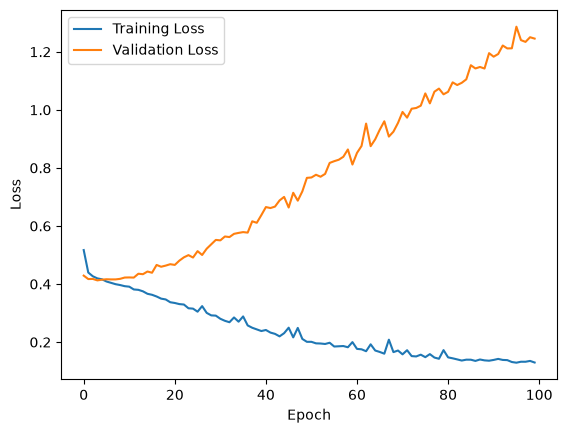

In [21]:
import matplotlib.pyplot as plt

plt.plot(history1.history['loss'], label='Training Loss')
plt.plot(history1.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

The history shows that the training loss gets smaller, while the validation loss gets bigger. We can conclude that the model overfitts the training data. To address the high variance, a less complex model architecture can be designed, as well as include a regularization parameter. 

In [22]:
#Try a less complex neural netowrk. Can help for overfitting.

model2 = Sequential([
    Input(shape=(40,)),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
    
])

model2.compile(optimizer='adam', loss=BinaryCrossentropy())

#Train model 
history2 = model2.fit(
    X_train_nn_scaled, y_train_nn, 
    validation_data=(X_val_nn_scaled, y_val_nn),
    epochs=100
)




Epoch 1/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.5432 - val_loss: 0.4629
Epoch 2/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 610us/step - loss: 0.4612 - val_loss: 0.4317
Epoch 3/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 605us/step - loss: 0.4416 - val_loss: 0.4225
Epoch 4/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 605us/step - loss: 0.4333 - val_loss: 0.4185
Epoch 5/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 597us/step - loss: 0.4273 - val_loss: 0.4171
Epoch 6/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 588us/step - loss: 0.4235 - val_loss: 0.4157
Epoch 7/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 588us/step - loss: 0.4205 - val_loss: 0.4153
Epoch 8/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 589us/step - loss: 0.4180 - val_loss: 0.4152
Epoch 9/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 584us/step - loss: 0.4155 - val_loss: 0.4152
Epoch 10/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 586us/step - loss: 0.4139 - val_loss: 0.4160
Epoch 11/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 593us/step - loss: 0.4119 - val_loss: 0.4160
Epoch 12/100
133/133 

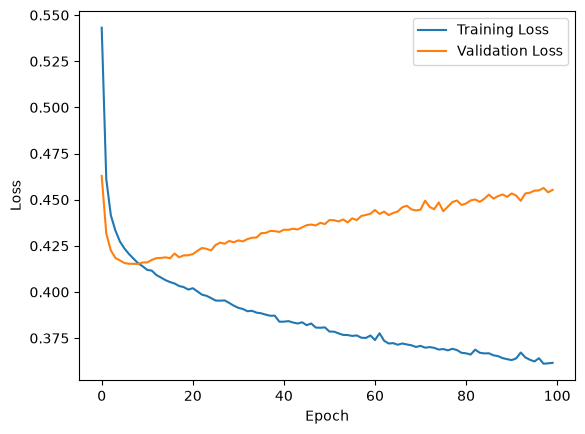

In [23]:
#Plot history for model2
plt.plot(history2.history['loss'], label='Training Loss')
plt.plot(history2.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [24]:
#After epoch 10, training loss and validation loss diverge greatly, still showing high variance problem. Lets try another model arquitecture.

model3 = Sequential([
    Input(shape=(X_train_nn_scaled.shape[1],)),
    Dense(8, activation='relu'),
    Dense(4, activation='relu'),
    Dense(1, activation='sigmoid')
    
])

model3.compile(optimizer='adam', loss=BinaryCrossentropy())

#Train model 
history3 = model3.fit(
    X_train_nn_scaled, y_train_nn, 
    validation_data=(X_val_nn_scaled, y_val_nn),
    epochs=50
)

Epoch 1/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.6474 - val_loss: 0.4941
Epoch 2/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 600us/step - loss: 0.4784 - val_loss: 0.4354
Epoch 3/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 582us/step - loss: 0.4510 - val_loss: 0.4243
Epoch 4/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 589us/step - loss: 0.4420 - val_loss: 0.4176
Epoch 5/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 586us/step - loss: 0.4366 - val_loss: 0.4147
Epoch 6/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 587us/step - loss: 0.4330 - val_loss: 0.4103
Epoch 7/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 589us/step - loss: 0.4300 - val_loss: 0.4076
Epoch 8/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 599us/step - loss: 0.4268 - val_loss: 0.4059
Epoch 9/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 595us/step - loss: 0.4241 - val_loss: 0.4032
Epoch 10/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 595us/step - loss: 0.4240 - val_loss: 0.4015
Epoch 11/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 586us/step - loss: 0.4212 - val_loss: 0.4007
Epoch 12/50
133/133 ━━━━━━━━━━━━

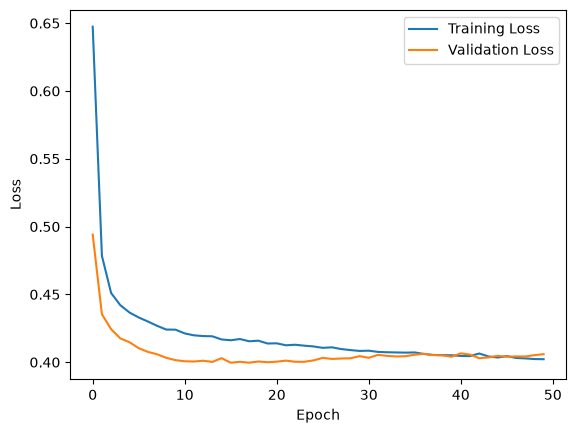

In [25]:
plt.plot(history3.history['loss'], label='Training Loss')
plt.plot(history3.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

Model 3 improves by lowering the variance and adapting better to new data.

Epoch 1/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 1.4058 - val_loss: 1.0011
Epoch 2/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 675us/step - loss: 0.8363 - val_loss: 0.6800
Epoch 3/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 658us/step - loss: 0.6280 - val_loss: 0.5564
Epoch 4/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 676us/step - loss: 0.5410 - val_loss: 0.4997
Epoch 5/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 675us/step - loss: 0.5044 - val_loss: 0.4749
Epoch 6/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 676us/step - loss: 0.4852 - val_loss: 0.4614
Epoch 7/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 655us/step - loss: 0.4720 - val_loss: 0.4561
Epoch 8/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 649us/step - loss: 0.4654 - val_loss: 0.4502
Epoch 9/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 644us/step - loss: 0.4629 - val_loss: 0.4465
Epoch 10/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 642us/step - loss: 0.4612 - val_loss: 0.4373
Epoch 11/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 645us/step - loss: 0.4575 - val_loss: 0.4381
Epoch 12/50
133/133 ━━━━━━━━━━━━

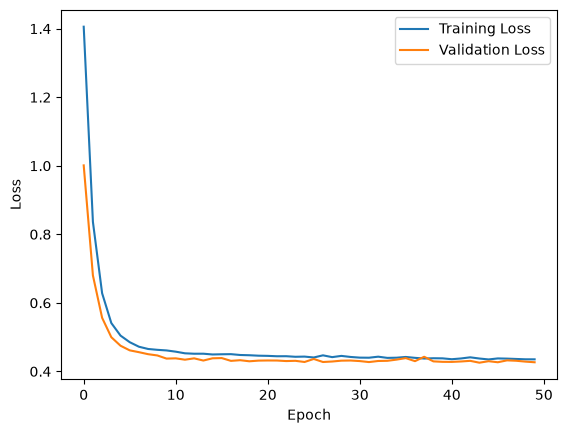

In [26]:
#Apply regularization for model1, model2 and model3
from tensorflow.keras.regularizers import l2

model1_r = Sequential([
    Input(shape=(40,)),
    Dense(40, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(64, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(32, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(1, activation='sigmoid')
    
])

model1_r.compile(optimizer='adam', loss=BinaryCrossentropy())

history1_r =  model1_r.fit(
    X_train_nn_scaled, y_train_nn, 
    validation_data=(X_val_nn_scaled, y_val_nn),
    epochs=50
)

plt.plot(history1_r.history['loss'], label='Training Loss')
plt.plot(history1_r.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


Model1 seems to better fit new data when applying L2 regularization.


Epoch 1/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.8628 - val_loss: 0.7039
Epoch 2/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 600us/step - loss: 0.6613 - val_loss: 0.5909
Epoch 3/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 600us/step - loss: 0.5810 - val_loss: 0.5346
Epoch 4/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 600us/step - loss: 0.5356 - val_loss: 0.5009
Epoch 5/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 598us/step - loss: 0.5076 - val_loss: 0.4787
Epoch 6/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 616us/step - loss: 0.4894 - val_loss: 0.4651
Epoch 7/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 601us/step - loss: 0.4771 - val_loss: 0.4571
Epoch 8/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 608us/step - loss: 0.4698 - val_loss: 0.4513
Epoch 9/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 597us/step - loss: 0.4640 - val_loss: 0.4466
Epoch 10/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 591us/step - loss: 0.4587 - val_loss: 0.4439
Epoch 11/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 605us/step - loss: 0.4560 - val_loss: 0.4382
Epoch 12/50
133/133 ━━━━━━━━━━━━

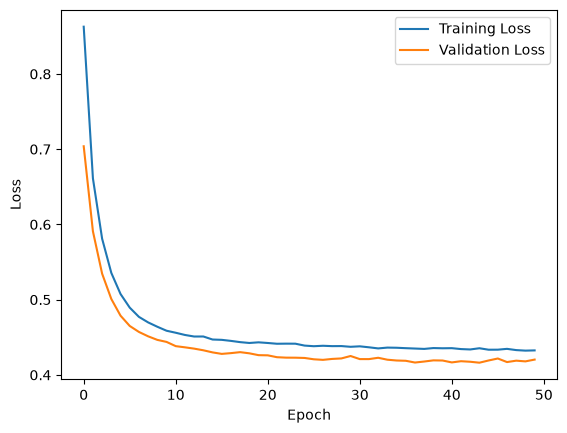

In [27]:
model2_r = Sequential([
    Input(shape=(40,)),
    Dense(16, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(8, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(1, activation='sigmoid')
    
])

model2_r.compile(optimizer='adam', loss=BinaryCrossentropy())

#Train model 
history2_r = model2_r.fit(
    X_train_nn_scaled, y_train_nn, 
    validation_data=(X_val_nn_scaled, y_val_nn),
    epochs=50
)

plt.plot(history2_r.history['loss'], label='Training Loss')
plt.plot(history2_r.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

Model2 with regularization improves as well.

Epoch 1/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.7852 - val_loss: 0.6787
Epoch 2/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 612us/step - loss: 0.6446 - val_loss: 0.5636
Epoch 3/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 606us/step - loss: 0.5656 - val_loss: 0.5320
Epoch 4/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 609us/step - loss: 0.5362 - val_loss: 0.5088
Epoch 5/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 588us/step - loss: 0.5170 - val_loss: 0.4926
Epoch 6/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 606us/step - loss: 0.5025 - val_loss: 0.4817
Epoch 7/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 601us/step - loss: 0.4917 - val_loss: 0.4721
Epoch 8/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 603us/step - loss: 0.4827 - val_loss: 0.4665
Epoch 9/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 596us/step - loss: 0.4769 - val_loss: 0.4586
Epoch 10/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 593us/step - loss: 0.4696 - val_loss: 0.4544
Epoch 11/100
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 598us/step - loss: 0.4647 - val_loss: 0.4509
Epoch 12/100
133/133 

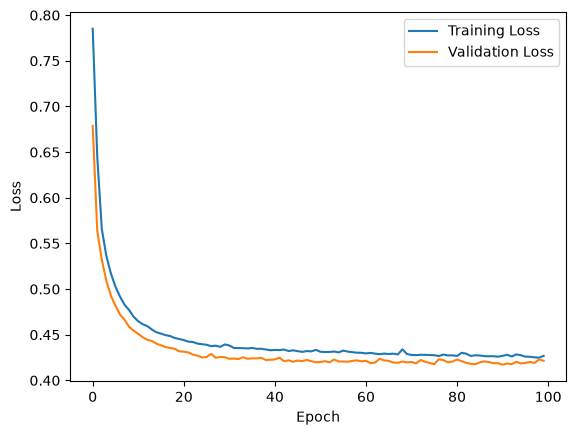

In [28]:
model3_r = Sequential([
    Input(shape=(X_train_nn_scaled.shape[1],)),
    Dense(8, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(4, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(1, activation='sigmoid')
    
])

model3_r.compile(optimizer='adam', loss=BinaryCrossentropy())

#Train model 
history3_r = model3_r.fit(
    X_train_nn_scaled, y_train_nn, 
    validation_data=(X_val_nn_scaled, y_val_nn),
    epochs=100
)

plt.plot(history3_r.history['loss'], label='Training Loss')
plt.plot(history3_r.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

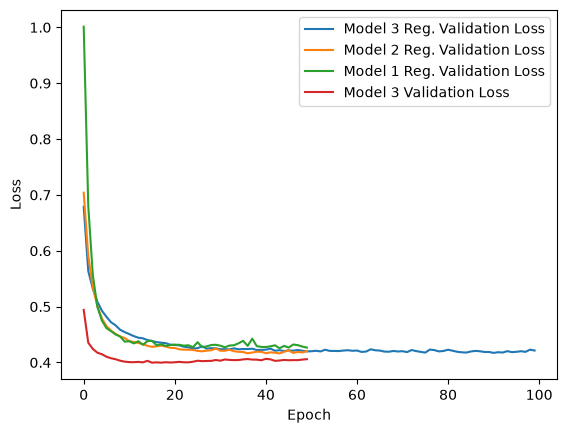

In [29]:
#Will select model3 without regularization as it gave the lower validation loss.
plt.plot(history3_r.history['val_loss'], label='Model 3 Reg. Validation Loss')
plt.plot(history2_r.history['val_loss'], label='Model 2 Reg. Validation Loss')
plt.plot(history1_r.history['val_loss'], label='Model 1 Reg. Validation Loss')
plt.plot(history3.history['val_loss'], label='Model 3 Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [30]:
#Evaluate model on test data
loss = model3.evaluate(X_test_nn_scaled, y_test_nn, verbose=0)
print(f"model3: loss={loss:.4f}")

#accuracy = count of right predictions/ all predictions. 
probabilities = model3.predict(X_test_nn_scaled)
y_hat_nn = (probabilities >= 0.5).astype(int)
y = y_test_nn.to_numpy().reshape(-1,1)
accuracy = np.mean(y_hat_nn == y)
accuracy

model3: loss=0.4212
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 666us/step


np.float64(0.7984386089425124)

Model reflects an accuracy of 79%. Since dataset label was skewed, almost 75% percent of examples were classified as No-Churn, the recall metric
will be a more accurate measure since it measures the percentage of how may positive predictions were made from all existing positive examples.

In [33]:
true_positives = np.sum((y == 1) & (y_hat_nn == 1))
actual_positives = np.sum(y == 1)

recall = true_positives / actual_positives
recall

np.float64(0.5191815856777494)

The recall turns out to be 48.3%, which means that the model identified less than half of customer churn. In other words, it failed to identify more than half of customer churns, which means that if the company were to use the trained model, it risks to overlook (not flag for retention outreach) more than half of customer churns. 

In [34]:
#Since we want to be able to identify more customer churns, we can lower the classification threshold. We gain more recall at the cost of lower precision.
y_hat_nn = (probabilities >= 0.4).astype(int)

true_positives = np.sum((y == 1) & (y_hat_nn == 1))
actual_positives = np.sum(y == 1)
recall = true_positives / actual_positives
print(recall)

0.6086956521739131


In [35]:
y_hat_nn = (probabilities >= 0.3).astype(int)

true_positives = np.sum((y == 1) & (y_hat_nn == 1))
actual_positives = np.sum(y == 1)
recall = true_positives / actual_positives
print(recall)

0.7493606138107417


By lowering the threshold, the model achieves approximately a 75% of recall, which means it is able to classify 75% of churn customers.

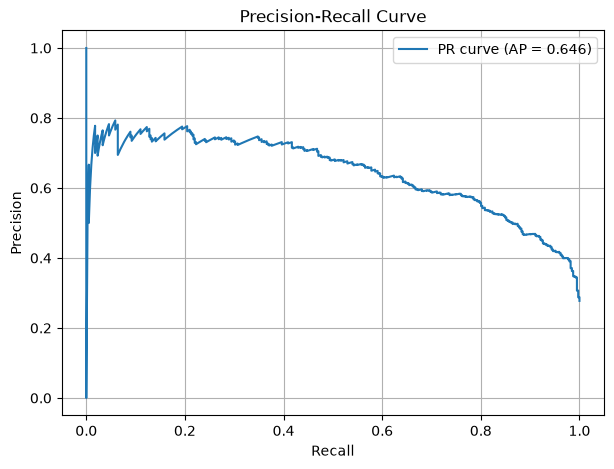

In [37]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# Use probabilities, not hard predictions
precision, recall, thresholds = precision_recall_curve(y, probabilities)

# Optional: compute the area under the curve as a single summary number
ap_score = average_precision_score(y, probabilities)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f'PR curve (AP = {ap_score:.3f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(True)
plt.show()